In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("StudentsPerformance.csv")

print(df.head())
print(df.info())
print(df.describe())


   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtyp

In [5]:
#حساب متوسط الدرجات لكل مادة
math_avg = df["math score"].mean()
reading_avg = df["reading score"].mean()
writing_avg = df["writing score"].mean()

print("Math:", math_avg)
print("Reading:", reading_avg)
print("Writing:", writing_avg)


Math: 66.089
Reading: 69.169
Writing: 68.054


In [8]:
#   هنا تمث اضافه عمود لمتوسط مجموع الدرجات عشان نجيب اعلى درجات واقل عشره طلاب
df["average_score"] = (
    df["math score"] +
    df["reading score"] +
    df["writing score"]
) / 3


In [9]:
top_students = df.sort_values(
    "average_score",
    ascending=False
).head(10)

print(top_students)


     gender race/ethnicity parental level of education         lunch  \
916    male        group E           bachelor's degree      standard   
962  female        group E          associate's degree      standard   
458  female        group E           bachelor's degree      standard   
114  female        group E           bachelor's degree      standard   
712  female        group D                some college      standard   
179  female        group D            some high school      standard   
165  female        group C           bachelor's degree      standard   
625    male        group D                some college      standard   
685  female        group E             master's degree      standard   
903  female        group D           bachelor's degree  free/reduced   

    test preparation course  math score  reading score  writing score  \
916               completed         100            100            100   
962                    none         100            100       

In [10]:
bottom_students = df.sort_values(
    "average_score",
    ascending=True
).head(10)

print(bottom_students)


     gender race/ethnicity parental level of education         lunch  \
59   female        group C            some high school  free/reduced   
980  female        group B                 high school  free/reduced   
596    male        group B                 high school  free/reduced   
327    male        group A                some college  free/reduced   
17   female        group B            some high school  free/reduced   
76     male        group E            some high school      standard   
601  female        group C                 high school      standard   
338  female        group B            some high school  free/reduced   
787  female        group B                some college      standard   
211    male        group C                some college  free/reduced   

    test preparation course  math score  reading score  writing score  \
59                     none           0             17             10   
980                    none           8             24       

In [11]:
# يتم التحليل الان  لمتوسط الدرجات للجنسين
gender_analysis = df.groupby("gender")[
    ["math score", "reading score", "writing score"]
].mean()

print(gender_analysis)



        math score  reading score  writing score
gender                                          
female   63.633205      72.608108      72.467181
male     68.728216      65.473029      63.311203


In [12]:
#تمت مقارنة متوسط درجات الطلاب حسب حالة إكمال دورة التحضير للاختبار.
prep_analysis = df.groupby("test preparation course")[
    ["math score", "reading score", "writing score"]
].mean()

print(prep_analysis)


                         math score  reading score  writing score
test preparation course                                          
completed                 69.695531      73.893855      74.418994
none                      64.077882      66.534268      64.504673


Text(0, 0.5, 'Math Score')

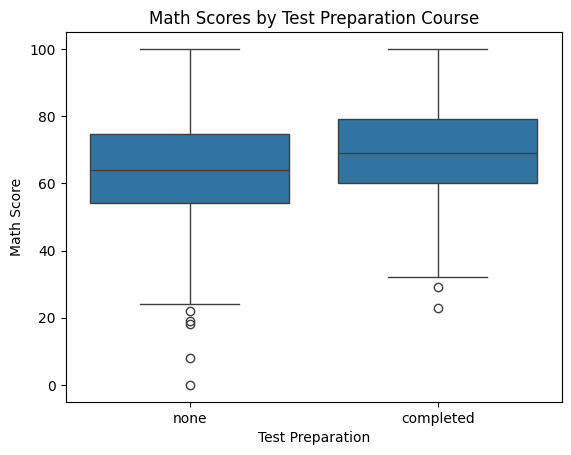

In [14]:
#  رسم بياني يوضح لي درجات الطلاب الي اكملو التحضير له والي ما اكملو التحضير
sns.boxplot(
    data=df,
    x="test preparation course",
    y="math score"
)

plt.title("Math Scores by Test Preparation Course")
plt.xlabel("Test Preparation")
plt.ylabel("Math Score")



في هذي البيانات فهمنا ان متوسط الدرجات للطلاب الذين اكملوا دورة التحضير درجاتهم اعلى من الي ما اكملوها
